### Shared subspace and proficiency probes across camera views (continuous 1 FPS windows)

`continuous_sampling.ipynb` embedded the **ego** video of every take as a contiguous 1 FPS window of up to 160
frames. Here the same analysis runs on each of the four **exo** cameras, with exactly the same seconds of the take
as its ego window (all five videos of a take are frame-aligned), so only the viewpoint changes. Exo frames
(796x448, or 448x796 for portrait cameras) are scaled to the ego frames' pixel budget (448x448 = 196 tokens per
frame pair) instead of their native size, which gives 576x320 / 320x576 frames (180 tokens per pair) and keeps the
token count, and hence memory, comparable with ego.

The camera numbering isn't consistent across takes (exo1 is a different position in different scenarios), so
besides each camera there is an **exo mean** view: the average of the four exo embeddings of a take, at each layer.

Each view gets its own CCA with the (shared, unchanged) commentary embeddings and its own probes, for the
fine-tuned model (LoRA checkpoint 50, fine-tuned on ego video only) and the zero-shot base model. The ego
embeddings are reused from `continuous_sampling.ipynb`'s cache.

In [1]:
import json
import re
from pathlib import Path

# Same data layout and preprocessing as continuous_sampling.ipynb, with every view's video path.
DATA_ROOT = next(
    p / "data" for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "annotations").is_dir()
)
ANNOTATION_ROOT = DATA_ROOT / "annotations"
COMMENTARY_ROOT = ANNOTATION_ROOT / "expert_commentary"

LEVELS = {
    "Novice": 1,
    "Early Expert": 2,
    "Intermediate Expert": 3,
    "Late Expert": 4,
}
CAMERA_VIEWS = ("ego", "exo1", "exo2", "exo3", "exo4")

# The commentary the model was trained on had the rating terms masked out; keep that.
RATING_TERMS = re.compile(
    r"\b(?:novice|early\s+expert|intermediate\s+expert|late\s+expert|"
    r"proficien\w*|rating|score|good\s+execution|tip\s+for\s+improvement|beginner)\b",
    flags=re.IGNORECASE,
)

def take_name(m):
    return m["video_paths"]["ego"].split("/")[1]

def video_path(m, video_type):
    parts = m["video_paths"][video_type].split("/")
    parts[-1:-1] = ["downscaled", "448"]
    return DATA_ROOT.joinpath(*parts)

def load_commentary(take):
    """The take's expert commentary in the training format (one block per expert), or None."""
    experts = []
    for data_path in sorted((COMMENTARY_ROOT / take).rglob("data.json")):
        transcript_path = data_path.parent / "transcriptions.json"
        if not transcript_path.exists():
            continue
        data = json.loads(data_path.read_text(encoding="utf-8"))
        transcripts = json.loads(transcript_path.read_text(encoding="utf-8"))
        segments = []
        for annotation in data.get("annotations", []):
            text = transcripts.get(annotation.get("recording_path"), {}).get("text", "").strip()
            if text:
                segments.append((annotation.get("video_time") or 0.0, RATING_TERMS.sub("[MASK]", text)))
        if segments:
            lines = "\n".join(f"[{t:.1f}s] {text}" for t, text in sorted(segments))
            experts.append(f"Expert {len(experts) + 1}:\n{lines}")
    if not experts:
        return None
    return "\n\n".join(experts)


with open("SkillFormer/annotation_test.jsonl", encoding="utf-8") as file:
    test_takes = {json.loads(line)["video_paths"][0].split("/")[1] for line in file}

def split_clips(split):
    """Takes with every view's video and commentary (the same takes as the ego-only notebooks: a take's
    downscaled ego video exists exactly when its exo videos do)."""
    annotation_file = "proficiency_demonstrator_train.json" if split == "train" else "proficiency_demonstrator_val.json"
    with open(ANNOTATION_ROOT / annotation_file, encoding="utf-8") as file:
        metadata = json.load(file)["annotations"]
    clips = []
    for m in metadata:
        if split == "test" and take_name(m) not in test_takes:
            continue
        if not all(video_path(m, view).exists() for view in CAMERA_VIEWS):
            continue
        commentary = load_commentary(take_name(m))
        if commentary is None:
            continue
        clips.append({"take_name": take_name(m), "scenario": m["scenario_name"],
                      "score": LEVELS[m["proficiency_score"]],
                      "videos": {view: str(video_path(m, view)) for view in CAMERA_VIEWS},
                      "commentary": commentary})
    return clips

clips_by_split = {split: split_clips(split) for split in ("train", "test")}
clips = clips_by_split["test"]
for split, split_list in clips_by_split.items():
    print(f"{split}: {len(split_list)} clips with every view and commentary")

train: 1174 clips with every view and commentary
test: 164 clips with every view and commentary


In [2]:
import numpy as np
import torch
from peft import PeftModel
from transformers import AutoModelForMultimodalLM, AutoProcessor, BitsAndBytesConfig
from transformers.video_utils import load_video

model_id = "Qwen/Qwen3.5-4B"
CHECKPOINT = "./qwen35-4b-finetuned/checkpoint-50"
WINDOW_FPS = 1
MAX_FRAMES = 160  # the ego windows' cap in continuous_sampling.ipynb

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True
)
base_model = AutoModelForMultimodalLM.from_pretrained(model_id, quantization_config=bnb_config, device_map="auto")
model = PeftModel.from_pretrained(base_model, CHECKPOINT).eval()
processor = AutoProcessor.from_pretrained(model_id)

# torchcodec can't load on this machine; decode with PyAV (see idea_1_midterm.ipynb).
def fetch_videos_pyav(video_url_or_urls, sample_indices_fn=None):
    if isinstance(video_url_or_urls, list):
        return list(zip(*[fetch_videos_pyav(x, sample_indices_fn) for x in video_url_or_urls]))
    return load_video(video_url_or_urls, backend="pyav", sample_indices_fn=sample_indices_fn)

processor.video_processor.fetch_videos = fetch_videos_pyav
processor.video_processor.fps = None
# Every frame gets at most the pixels of a 448x448 ego frame, whatever the number of frames: ego frames keep
# their size (as in continuous_sampling.ipynb) and 796x448 exo frames are scaled to 576x320.
processor.video_processor.size = {"shortest_edge": processor.video_processor.size.shortest_edge, "longest_edge": 10**12}
processor.video_processor.cap_pixels_per_frame = True
processor.video_processor.max_video_tokens = 448 * 448 // 32 ** 2  # per-frame cap, in 32x32 patches

_window = None  # the take's ego window {"start_s", "num_frames", ...} while one of its views is being loaded

def ego_window(metadata, **kwargs):
    """Frame indices of the take's ego window: the same seconds of the take, seen from another camera."""
    step = round(metadata.fps / WINDOW_FPS)
    indices = round(_window["start_s"] * metadata.fps) + step * np.arange(_window["num_frames"])
    assert indices[-1] < metadata.total_num_frames, (metadata, _window)
    return indices

# Replaces the uniform sampling; the processor calls it with the decoded video's metadata.
processor.video_processor.sample_frames = ego_window

VIDEO_TOKEN_ID = processor.tokenizer.convert_tokens_to_ids("<|video_pad|>")

W1112 17:01:23.516000 22776 site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


Loading weights:   0%|          | 0/723 [00:00<?, ?it/s]

In [3]:
# Mean-pool every decoder layer's output inside a forward hook, so the full (seq_len, 2560) hidden
# states of all 32 layers never have to be kept around. Layer k's entry is the residual stream after
# decoder layer k (1-indexed); the last one is taken before the final RMSNorm, like the others.
DECODER_LAYERS = [m for m in model.modules() if type(m).__name__ == "Qwen3_5DecoderLayer"]
assert len(DECODER_LAYERS) == base_model.config.text_config.num_hidden_layers

_pool_mask, _pooled = None, []

def _pool_hook(module, args, output):
    if _pool_mask is None:
        return
    hidden = output[0] if isinstance(output, tuple) else output
    _pooled.append(hidden[0, _pool_mask].float().mean(0).cpu())

for layer in DECODER_LAYERS:
    layer.register_forward_hook(_pool_hook)

@torch.inference_mode()
def layer_means(batch, mask):
    """(num_layers, hidden) mean of each decoder layer's output over the positions where mask is True."""
    global _pool_mask
    assert mask.any(), "nothing to pool over"
    _pool_mask = mask.to(model.device)
    _pooled.clear()
    try:
        with torch.autocast("cuda", dtype=torch.bfloat16):  # training and evaluation ran under bf16 autocast
            model(**batch.to(model.device), logits_to_keep=1)
    finally:
        _pool_mask = None
    return torch.stack(_pooled)

def video_embeddings(clip, view, window):
    """One exo view of the clip over its ego window, alone with no text, pooled over the video tokens:
    {"checkpoint-50": ..., "base": ..., plus the window}. Both models see the same decoded frames."""
    global _window
    _window = window
    batch = processor.apply_chat_template(
        [{"role": "user", "content": [{"type": "video", "video": clip["videos"][view]}]}],
        tokenize=True,
        return_dict=True,
        return_tensors="pt",
    )
    t, h, w = batch["video_grid_thw"][0].tolist()
    assert 2 * t == window["num_frames"] and sorted((h, w)) == [20, 36], (batch["video_grid_thw"], window)
    mask = batch["input_ids"][0] == VIDEO_TOKEN_ID
    embeddings = {Path(CHECKPOINT).name: layer_means(batch, mask)}
    with model.disable_adapter():
        embeddings["base"] = layer_means(batch, mask)
    return {**embeddings, **window}

In [4]:
import functools

from tqdm.auto import tqdm

# Raw (uncentered) per-layer means for every clip and view, cached per view and split so an interrupted run resumes.
EMBEDDING_DIR = Path("embeddings")
MODEL_NAMES = {Path(CHECKPOINT).name: "Fine-tuned", "base": "Zero-shot"}
EXO_VIEWS = CAMERA_VIEWS[1:]

def cache_path(view, split):
    suffix = "" if view == "ego" else f"_{view}"  # the ego cache is continuous_sampling.ipynb's
    return EMBEDDING_DIR / f"qwen35_continuous{WINDOW_FPS}fps{MAX_FRAMES}{suffix}_{split}_raw.pt"

ego_raw = {split: torch.load(cache_path("ego", split)) for split in ("test", "train")}

def embed_view(view, split):
    """{take name: video_embeddings(clip, view, its ego window)} for every clip of the split."""
    split_list = clips_by_split[split]
    raw_path = cache_path(view, split)
    raw = torch.load(raw_path) if raw_path.exists() else {}
    todo = [clip for clip in split_list if clip["take_name"] not in raw]
    print(f"{view} {split}: {len(split_list) - len(todo)} clips already embedded, {len(todo)} to go")
    for k, clip in enumerate(tqdm(todo), 1):
        ego = ego_raw[split][clip["take_name"]]
        window = {key: ego[key] for key in ("start_s", "num_frames", "clip_s")}
        raw[clip["take_name"]] = video_embeddings(clip, view, window)
        if k % 25 == 0:
            torch.save(raw, raw_path)
    torch.save(raw, raw_path)
    return raw

view_raw = {"ego": ego_raw}
for view in EXO_VIEWS:
    view_raw[view] = {split: embed_view(view, split) for split in ("test", "train")}

exo1 test: 0 clips already embedded, 164 to go


  0%|          | 0/164 [00:00<?, ?it/s]

[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.


[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


exo1 train: 0 clips already embedded, 1174 to go


  0%|          | 0/1174 [00:00<?, ?it/s]

... (8 outputs left out)

exo4 test: 0 clips already embedded, 164 to go


  0%|          | 0/164 [00:00<?, ?it/s]

exo4 train: 0 clips already embedded, 1174 to go


  0%|          | 0/1174 [00:00<?, ?it/s]

In [5]:
@functools.cache
def text_embeddings(split, model_name):
    """(clips, 32 layers, 2560) commentary embeddings from the midterm cache: they don't depend on the video."""
    midterm = torch.load(EMBEDDING_DIR / f"qwen35_{model_name}_{split}_raw.pt")
    return torch.stack([midterm[clip["take_name"]]["text"] for clip in clips_by_split[split]])

def video_embeddings_of(view, split, model_name):
    """(clips, 32 layers, 2560) video embeddings of one view; "exo mean" averages the four exo cameras."""
    if view == "exo mean":
        return torch.stack([video_embeddings_of(exo, split, model_name) for exo in EXO_VIEWS]).mean(0)
    raw = view_raw[view][split]
    return torch.stack([raw[clip["take_name"]][model_name] for clip in clips_by_split[split]])

VIEWS = (*CAMERA_VIEWS, "exo mean")
# {(view, model name): {split: (video, text)}}
raw_embeddings = {(view, model_name): {split: (video_embeddings_of(view, split, model_name), text_embeddings(split, model_name))
                                       for split in ("test", "train")}
                  for view in VIEWS for model_name in MODEL_NAMES}
text_embeddings.cache_clear()
del view_raw, ego_raw  # everything needed is in raw_embeddings now
print(f"{len(raw_embeddings)} (view, model) pairs; test video {tuple(raw_embeddings['ego', 'base']['test'][0].shape)}, "
      f"train video {tuple(raw_embeddings['ego', 'base']['train'][0].shape)}")

12 (view, model) pairs; test video (164, 32, 2560), train video (1174, 32, 2560)


#### Shared subspace (CCA) per view

As in the midterm: PCA-128 per modality (fit on train), CCA on the train pairs, scored on the held-out test pairs
against a permutation floor. Since the first ~5 components are scenario identity in every setting so far, the
summary also averages the test correlation over the **non-scenario** components only (scenario eta² < 0.5).

In [6]:
from sklearn.cross_decomposition import CCA
from sklearn.decomposition import PCA

LAYERS = {"early": 8, "middle": 16, "last": 32}
N_COMPONENTS = 32
PCA_DIMS = 128  # per modality, before CCA; exact SVD so reruns give identical results
N_PERMUTATIONS = 1000

def canonical_correlations(video_shared, text_shared):
    """Pearson correlation between each pair of canonical variates (one per component)."""
    v = video_shared - video_shared.mean(0)
    t = text_shared - text_shared.mean(0)
    return (v * t).sum(0) / np.sqrt((v ** 2).sum(0) * (t ** 2).sum(0))

def scenario_eta2(shared, scenarios):
    """Share of each canonical variate's variance that lies between scenarios (1 = pure scenario identity)."""
    within = sum(((shared[scenarios == s] - shared[scenarios == s].mean(0)) ** 2).sum(0) for s in np.unique(scenarios))
    return 1 - within / ((shared - shared.mean(0)) ** 2).sum(0)

test_scenarios = np.array([clip["scenario"] for clip in clips])

def fit_cca(raw_embeddings):
    """PCA + CCA on the train pairs at each layer in LAYERS, scored on the test pairs."""
    train_video_all, train_text_all = raw_embeddings["train"]
    video_all, text_all = raw_embeddings["test"]
    rng = np.random.default_rng(0)
    results = {}
    for name, layer in LAYERS.items():
        V_train = train_video_all[:, layer - 1].double().numpy()
        T_train = train_text_all[:, layer - 1].double().numpy()
        V_test = video_all[:, layer - 1].double().numpy()
        T_test = text_all[:, layer - 1].double().numpy()

        pca_video = PCA(PCA_DIMS, svd_solver="full").fit(V_train)
        pca_text = PCA(PCA_DIMS, svd_solver="full").fit(T_train)
        cca = CCA(n_components=N_COMPONENTS, max_iter=2000).fit(pca_video.transform(V_train), pca_text.transform(T_train))
        V_shared, T_shared = cca.transform(pca_video.transform(V_test), pca_text.transform(T_test))

        # The video canonical variates are affine in the embedding, u = (v - pca mean) @ directions + offset, so
        # the span of `directions` is the shared subspace in the model's 2560-d hidden-state space.
        directions = pca_video.components_.T @ (cca.x_rotations_ / cca._x_std[:, None])
        offset = -(cca._x_mean / cca._x_std) @ cca.x_rotations_
        assert np.allclose((V_test - pca_video.mean_) @ directions + offset, V_shared, atol=1e-6)

        test_corr = canonical_correlations(V_shared, T_shared)
        null = np.stack([canonical_correlations(V_shared, T_shared[rng.permutation(len(T_shared))])
                         for _ in range(N_PERMUTATIONS)])
        results[name] = {
            "layer": layer, "pca_video": pca_video, "cca": cca,
            "mean": pca_video.mean_,  # train mean of the video embeddings
            "basis": np.linalg.qr(directions)[0],  # orthonormal (2560, N_COMPONENTS) basis of the shared subspace
            "test_corr": test_corr,
            "null_95": np.quantile(null, 0.95, axis=0),  # one-sided: 95th percentile of shuffled-pair correlations
            "scenario_eta2": scenario_eta2(V_shared, test_scenarios),
        }
    return results

cca_results = {key: fit_cca(embeddings) for key, embeddings in tqdm(raw_embeddings.items())}

print("Held-out canonical correlations per view: components above the permutation 95th percentile, mean test r,"
      " and mean test r over the non-scenario components (scenario eta2 < 0.5; count in brackets)\n")
for model_name, model_label in MODEL_NAMES.items():
    print(f"{model_label:<12}" + "".join(f"{f'{name} (layer {layer})':>30}" for name, layer in LAYERS.items()))
    for view in VIEWS:
        cells = []
        for name in LAYERS:
            result = cca_results[view, model_name][name]
            above = int((result["test_corr"] > result["null_95"]).sum())
            non_scenario = result["scenario_eta2"] < 0.5
            cells.append(f"{above:>2}/{N_COMPONENTS}  {result['test_corr'].mean():.3f}  "
                         f"{result['test_corr'][non_scenario].mean():.3f} [{non_scenario.sum():>2}]")
        print(f"  {view:<10}" + "".join(f"{c:>30}" for c in cells))
    print()

  0%|          | 0/12 [00:00<?, ?it/s]

Held-out canonical correlations per view: components above the permutation 95th percentile, mean test r, and mean test r over the non-scenario components (scenario eta2 < 0.5; count in brackets)

Fine-tuned                 early (layer 8)             middle (layer 16)               last (layer 32)
  ego             32/32  0.587  0.513 [27]      31/32  0.563  0.485 [27]      30/32  0.596  0.523 [27]
  exo1            32/32  0.579  0.504 [27]      30/32  0.575  0.498 [27]      32/32  0.621  0.552 [27]
  exo2            31/32  0.561  0.483 [27]      31/32  0.576  0.501 [27]      31/32  0.632  0.565 [27]
  exo3            31/32  0.552  0.472 [27]      31/32  0.542  0.460 [27]      32/32  0.588  0.514 [27]
  exo4            32/32  0.549  0.468 [27]      30/32  0.543  0.461 [27]      31/32  0.600  0.528 [27]
  exo mean        32/32  0.590  0.517 [27]      32/32  0.602  0.530 [27]      32/32  0.646  0.582 [27]

Zero-shot                  early (layer 8)             middle (layer 16)          

#### Linear probes for proficiency per view

The same probes as the midterm and `continuous_sampling.ipynb`: the train-mean-centered video embedding (**full**),
its projection onto the view's 32-d CCA subspace (**shared**), the remainder (**residual**), and the controls
(**PCA-128**, **top-32 PCA**, **random** 32-d subspaces of PCA-128, mean of 10 draws), each a logistic regression
(regularization by 5-fold CV on train) trained on the train clips and scored on the test clips.

In [7]:
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

train_scores = np.array([clip["score"] for clip in clips_by_split["train"]])
test_scores = np.array([clip["score"] for clip in clips])

N_RANDOM_SUBSPACES = 10

def project(video, result, basis):
    """Train-mean-centered video embeddings projected onto the span of the orthonormal columns of basis."""
    return (video - result["mean"]) @ basis @ basis.T

def split_shared_residual(video, result):
    """(shared, residual) parts of video embeddings; shared + residual = video - train mean."""
    shared = project(video, result, result["basis"])
    return shared, video - result["mean"] - shared

def probe(train_x, test_x):
    """Test accuracy and balanced accuracy of a logistic-regression probe trained on the train clips."""
    model = make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=np.logspace(-4, 2, 13), cv=5, max_iter=5000, n_jobs=-1))
    model.fit(train_x, train_scores)
    pred = model.predict(test_x)
    return accuracy_score(test_scores, pred), balanced_accuracy_score(test_scores, pred)

majority = np.bincount(train_scores).argmax()  # train's most common level, predicted for every test clip
# Each test clip gets the most common train level of its own scenario (ties go to the lower level).
train_scenarios = np.array([clip["scenario"] for clip in clips_by_split["train"]])
scenario_majority = {s: np.bincount(train_scores[train_scenarios == s]).argmax() for s in np.unique(train_scenarios)}
scenario_majority_pred = np.array([scenario_majority[clip["scenario"]] for clip in clips])
baselines = {
    "majority class": (accuracy_score(test_scores, np.full_like(test_scores, majority)),
                       balanced_accuracy_score(test_scores, np.full_like(test_scores, majority))),
    "per-scenario majority": (accuracy_score(test_scores, scenario_majority_pred),
                              balanced_accuracy_score(test_scores, scenario_majority_pred)),
}

def probe_representation(raw_embeddings, cca_results):
    """Probe results at each layer for one view and model: the full embedding, its shared and residual parts, and
    the controls (the PCA-128 space CCA works in, its top 32 components, and random 32-d subspaces of it: mean and sd)."""
    train_video_all, video_all = raw_embeddings["train"][0], raw_embeddings["test"][0]
    results = {}
    for name, result in cca_results.items():
        layer = result["layer"]
        train_video = train_video_all[:, layer - 1].double().numpy()
        test_video = video_all[:, layer - 1].double().numpy()
        train_shared, train_residual = split_shared_residual(train_video, result)
        test_shared, test_residual = split_shared_residual(test_video, result)
        results[f"{name} (layer {layer}): full"] = probe(train_video - result["mean"], test_video - result["mean"])
        results[f"{name} (layer {layer}): shared"] = probe(train_shared, test_shared)
        results[f"{name} (layer {layer}): residual"] = probe(train_residual, test_residual)
        pca_basis = result["pca_video"].components_.T  # (2560, PCA_DIMS), orthonormal, by decreasing variance
        results[f"{name} (layer {layer}): pca128"] = probe(project(train_video, result, pca_basis),
                                                          project(test_video, result, pca_basis))
        results[f"{name} (layer {layer}): pca32"] = probe(project(train_video, result, pca_basis[:, :N_COMPONENTS]),
                                                         project(test_video, result, pca_basis[:, :N_COMPONENTS]))
        random_results = []
        for seed in range(N_RANDOM_SUBSPACES):
            # A random orthonormal 32-d basis of the PCA-128 space, the space CCA picks its directions from.
            rotation = np.linalg.qr(np.random.default_rng(seed).standard_normal((PCA_DIMS, N_COMPONENTS)))[0]
            basis = pca_basis @ rotation
            random_results.append(probe(project(train_video, result, basis), project(test_video, result, basis)))
        results[f"{name} (layer {layer}): random"] = tuple(np.mean(random_results, axis=0))
        results[f"{name} (layer {layer}): random sd"] = tuple(np.std(random_results, axis=0))
    return results

probe_results = {key: probe_representation(raw_embeddings[key], cca_results[key]) for key in tqdm(raw_embeddings)}

  0%|          | 0/12 [00:00<?, ?it/s]

In [8]:
# Test accuracy / balanced accuracy per view, one block per model; then the accuracies as LaTeX tables
# (booktabs; best per column in bold).
PARTS = {"full": "Full", "shared": "Shared (CCA)", "residual": "Residual", "pca128": "PCA-128",
         "pca32": "Top-32 PCA", "random": "Random 32-d in PCA-128"}
rows = [(f"{name} (layer {layer}): {part}", layer, part) for name, layer in LAYERS.items() for part in PARTS]

print(f"Proficiency probes on video embeddings ({len(train_scores)} train / {len(test_scores)} test clips): "
      f"accuracy / balanced accuracy\n")
for model_name in reversed(MODEL_NAMES):
    print(f"{MODEL_NAMES[model_name]:<32}" + "".join(f"{view:>15}" for view in VIEWS))
    for key, _, part in rows:
        print(f"{key:<32}" + "".join(f"{probe_results[view, model_name][key][0]:>7.3f} / {probe_results[view, model_name][key][1]:.3f}"
                                     for view in VIEWS))
        if part == "random":
            print(f"{'  (sd over random subspaces)':<32}"
                  + "".join(f"{probe_results[view, model_name][key + ' sd'][0]:>7.3f} / {probe_results[view, model_name][key + ' sd'][1]:.3f}"
                            for view in VIEWS))
    print()
for baseline, (acc, balanced) in baselines.items():
    print(f"{baseline:<32}{acc:>7.3f} / {balanced:.3f}")
print(f"\nChance balanced accuracy: 0.250; one test clip = {1 / len(test_scores):.3f} accuracy")

def latex_table(model_name):
    results = {view: probe_results[view, model_name] for view in VIEWS}
    best = {view: max(round(results[view][key][0], 3) for key, _, _ in rows) for view in VIEWS}
    cell = lambda view, accuracy: rf"\textbf{{{accuracy:.3f}}}" if round(accuracy, 3) == best[view] else f"{accuracy:.3f}"
    latex = [
        r"\begin{table}[t]", r"\centering", r"\small",
        rf"\caption{{Test accuracy of logistic-regression probes predicting proficiency from {MODEL_NAMES[model_name].lower()} "
        r"Qwen3.5-4B video embeddings of each camera view (mean-pooled over the video tokens after the given decoder "
        rf"layer), trained on the {len(train_scores):,} train takes and evaluated on the {len(test_scores)} test takes. "
        rf"Every view covers the same contiguous {WINDOW_FPS}~FPS window of up to {MAX_FRAMES} frames per take; exo "
        r"frames are scaled to the pixel count of a 448$\times$448 ego frame. Exo mean: the average of the four exo "
        r"embeddings. Representations as in Table~\ref{tab:continuous-probes}; each view uses its own CCA subspace.}",
        rf"\label{{tab:view-probes-{MODEL_NAMES[model_name].lower()}}}", r"\begin{tabular}{ll" + "c" * len(VIEWS) + "}",
        r"\toprule",
        r"Layer & Representation & " + " & ".join(view.capitalize() for view in VIEWS) + r" \\", r"\midrule",
    ]
    for k, (key, layer, part) in enumerate(rows):
        if part == "full" and k:
            latex.append(r"\midrule")
        latex.append(f"{layer if part == 'full' else ''} & {PARTS[part]} & "
                     + " & ".join(cell(view, results[view][key][0]) for view in VIEWS) + r" \\")
    latex += [r"\midrule"] + [
        rf"{baseline.capitalize()} & & \multicolumn{{{len(VIEWS)}}}{{c}}{{{acc:.3f}}} \\" for baseline, (acc, _) in baselines.items()
    ] + [r"\bottomrule", r"\end{tabular}", r"\end{table}"]
    return "\n".join(latex)

for model_name in reversed(MODEL_NAMES):
    print("\n" + latex_table(model_name))

Proficiency probes on video embeddings (1174 train / 164 test clips): accuracy / balanced accuracy

Zero-shot                                   ego           exo1           exo2           exo3           exo4       exo mean
early (layer 8): full             0.402 / 0.416  0.384 / 0.398  0.433 / 0.444  0.476 / 0.466  0.463 / 0.482  0.415 / 0.443
early (layer 8): shared           0.427 / 0.415  0.341 / 0.320  0.433 / 0.394  0.378 / 0.394  0.421 / 0.406  0.439 / 0.424
early (layer 8): residual         0.390 / 0.407  0.409 / 0.441  0.415 / 0.413  0.482 / 0.509  0.470 / 0.534  0.409 / 0.455
early (layer 8): pca128           0.421 / 0.443  0.378 / 0.451  0.421 / 0.383  0.427 / 0.434  0.494 / 0.508  0.433 / 0.440
early (layer 8): pca32            0.463 / 0.402  0.427 / 0.433  0.378 / 0.412  0.402 / 0.418  0.421 / 0.437  0.415 / 0.404
early (layer 8): random           0.426 / 0.382  0.423 / 0.432  0.393 / 0.392  0.413 / 0.433  0.395 / 0.368  0.435 / 0.440
  (sd over random subspaces)      0.023

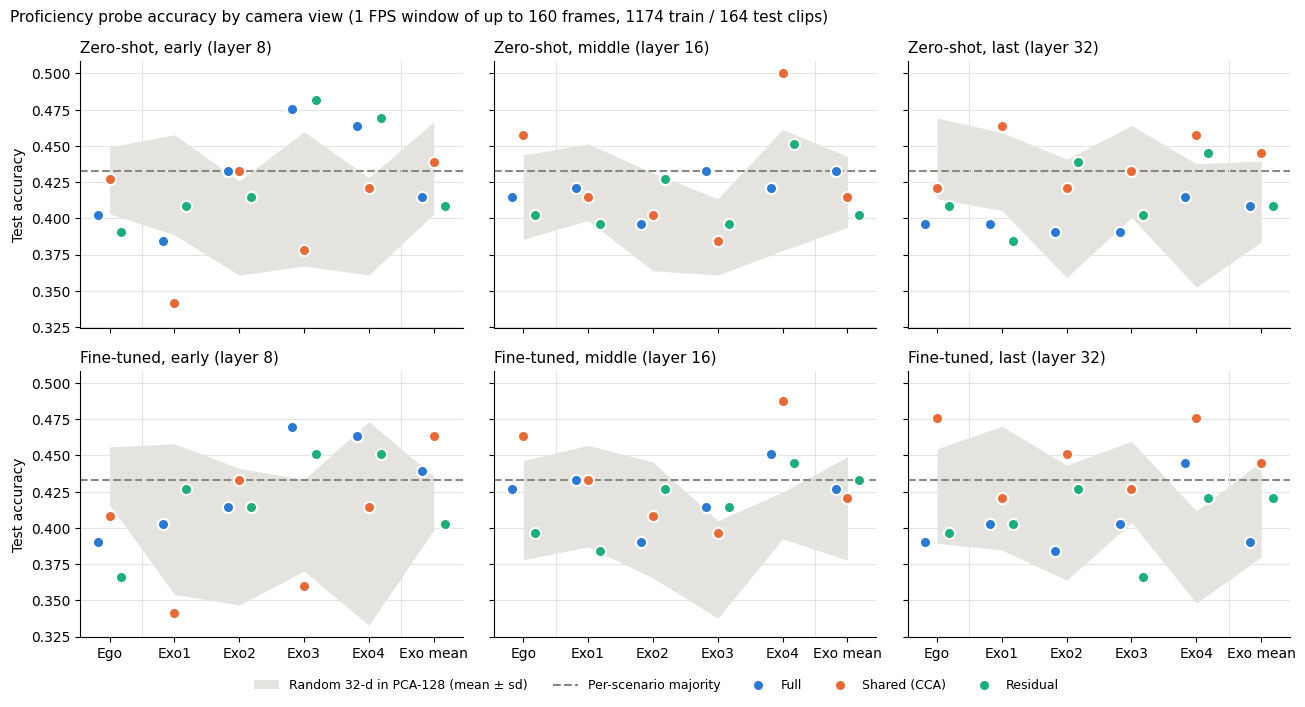

In [9]:
import matplotlib.pyplot as plt

# Probe accuracy by view: full / shared / residual as dots, the random-subspace control as a band (mean +- sd),
# and the per-scenario majority baseline as a dashed line.
PART_COLORS = {"full": "#2a78d6", "shared": "#eb6834", "residual": "#1baf7a"}
NULL_COLOR, GRID_COLOR, BAND_COLOR = "#8a8984", "#e4e3df", "#e4e3df"
x = np.arange(len(VIEWS))
offsets = dict(zip(PART_COLORS, (-0.18, 0, 0.18)))

fig, axes = plt.subplots(len(MODEL_NAMES), len(LAYERS), figsize=(4.4 * len(LAYERS), 3.4 * len(MODEL_NAMES)),
                         sharex=True, sharey=True)
for row, model_name in zip(axes, reversed(MODEL_NAMES)):
    for ax, (name, layer) in zip(row, LAYERS.items()):
        results = [probe_results[view, model_name] for view in VIEWS]
        random_mean = np.array([r[f"{name} (layer {layer}): random"][0] for r in results])
        random_sd = np.array([r[f"{name} (layer {layer}): random sd"][0] for r in results])
        ax.fill_between(x, random_mean - random_sd, random_mean + random_sd, color=BAND_COLOR, lw=0,
                        label="Random 32-d in PCA-128 (mean ± sd)")
        ax.axhline(baselines["per-scenario majority"][0], color=NULL_COLOR, lw=1.5, ls="--", label="Per-scenario majority")
        for part, color in PART_COLORS.items():
            ax.plot(x + offsets[part], [r[f"{name} (layer {layer}): {part}"][0] for r in results], ls="none",
                    marker="o", ms=8, color=color, markeredgecolor="white", markeredgewidth=1.5, label=PARTS[part])
        ax.set_title(f"{MODEL_NAMES[model_name]}, {name} (layer {layer})", loc="left", fontsize=11)
        ax.set_xticks(x, [view.capitalize() for view in VIEWS])
        ax.axvline(0.5, color=GRID_COLOR, lw=0.8)  # ego | exo cameras
        ax.axvline(len(CAMERA_VIEWS) - 0.5, color=GRID_COLOR, lw=0.8)  # exo cameras | exo mean
        ax.grid(axis="y", color=GRID_COLOR, lw=0.8)
        ax.set_axisbelow(True)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
    row[0].set_ylabel("Test accuracy")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, fontsize=9, ncol=len(labels), loc="lower center", bbox_to_anchor=(0.5, -0.04))
fig.suptitle(f"Proficiency probe accuracy by camera view ({WINDOW_FPS} FPS window of up to {MAX_FRAMES} frames, "
             f"{len(train_scores)} train / {len(test_scores)} test clips)", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
Path("figures").mkdir(exist_ok=True)
fig.savefig(f"figures/probe_accuracy_by_view_continuous{WINDOW_FPS}fps{MAX_FRAMES}.png", dpi=200, bbox_inches="tight")
plt.show()